        # Cognitive Science (1204 427) — Lab 04
        ## Problem Solving: BFS versus A* on the 8-Puzzle

        **ระดับ:** ปริญญาตรี  
        **เวลาที่แนะนำ:** 150–180 นาที  
        **รูปแบบ:** งานเดี่ยวบน Google Colab/Jupyter Notebook  
        **แพ็กเกจหลัก:** `heapq, collections, numpy, pandas, matplotlib`

        ### แนวคิดสำคัญ

        BFS ค้นหาแบบไม่ใช้ความรู้เฉพาะปัญหา ส่วน A* ใช้ Heuristic เพื่อจัดลำดับ State ที่น่าจะนำไปสู่เป้าหมายเร็วกว่า Lab นี้เชื่อมโยง Human Problem Solving กับ Computational Search

        ### วัตถุประสงค์

        เปรียบเทียบ Solution Length, Expanded Nodes และ Runtime ของ BFS กับ A* พร้อมวิพากษ์คุณสมบัติของ Heuristic

        ### งานที่ต้องทำ

        1. สร้างสถานะเริ่มต้นที่แก้ได้จากการ Scramble เป้าหมาย
2. แก้ปัญหาด้วย BFS และ A* Manhattan Distance
3. เปรียบเทียบอย่างน้อย 3 ระดับความยาก
4. ตรวจว่า Algorithm ให้ Solution Length เท่ากันหรือไม่
5. Required Extension: เพิ่ม Misplaced Tiles Heuristic

        > ไปที่ [Google Colab](https://colab.research.google.com) แล้วเลือก **File → Upload notebook** เพื่อเปิดไฟล์นี้


## ข้อมูลนิสิตและคำชี้แจง

- ชื่อ–สกุล: วชิรวิทย์ วงค์แสง
- รหัสนิสิต: 67011212055
- กลุ่มเรียน: 1

1. เปลี่ยน `STUDENT_ID` เป็นรหัสนิสิตของตนเองก่อนรันโปรแกรม
2. รหัส 4 หลักสุดท้ายใช้เป็น Random Seed ทำให้ข้อมูลแต่ละคนแตกต่างกัน
3. รันเซลล์จากบนลงล่างและเก็บ Output ไว้ในไฟล์ที่ส่ง
4. ทุกกราฟต้องมีชื่อกราฟ ชื่อแกน หน่วย และคำอธิบาย
5. ห้ามสรุปผลเกินกว่าหลักฐานจากข้อมูลหรืออ้างว่าข้อมูลจำลองเป็นข้อมูลมนุษย์จริง
6. ส่งไฟล์ `.ipynb` และ `.pdf` โดยตั้งชื่อ `StudentID_LabXX.ipynb`


In [1]:
STUDENT_ID = 67011212055  # รหัสนิสิต: วชิรวิทย์ วงค์แสง
sid = str(STUDENT_ID).strip()
if not sid.isdigit() or len(sid) < 4:
    raise ValueError("STUDENT_ID ต้องเป็นตัวเลขอย่างน้อย 4 หลัก")
seed = int(sid[-4:])
print(f"Student ID: {sid} | Random seed: {seed}")


Student ID: 67011212055 | Random seed: 2055


In [2]:
import heapq
import time
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed + 40)
GOAL = (1, 2, 3, 4, 5, 6, 7, 8, 0)

def neighbors(state):
    zero = state.index(0); row, col = divmod(zero, 3)
    result = []
    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nr, nc = row + dr, col + dc
        if 0 <= nr < 3 and 0 <= nc < 3:
            j = nr * 3 + nc
            new = list(state); new[zero], new[j] = new[j], new[zero]
            result.append(tuple(new))
    return result

def scramble(steps):
    state = GOAL; previous = None
    for _ in range(steps):
        choices = [s for s in neighbors(state) if s != previous]
        previous, state = state, choices[rng.integers(len(choices))]
    return state

def manhattan(state):
    total = 0
    for i, tile in enumerate(state):
        if tile != 0:
            goal_i = tile - 1
            total += abs(i // 3 - goal_i // 3) + abs(i % 3 - goal_i % 3)
    return total


In [3]:
def bfs(start, max_expand=200000):
    queue = deque([(start, 0)]); visited = {start}; expanded = 0
    while queue:
        state, depth = queue.popleft(); expanded += 1
        if state == GOAL: return depth, expanded
        if expanded >= max_expand: return None, expanded
        for nxt in neighbors(state):
            if nxt not in visited:
                visited.add(nxt); queue.append((nxt, depth + 1))
    return None, expanded

def astar(start, heuristic=manhattan, max_expand=200000):
    heap = [(heuristic(start), 0, start)]; best_g = {start: 0}; expanded = 0
    while heap:
        _, g, state = heapq.heappop(heap)
        if g != best_g.get(state): continue
        expanded += 1
        if state == GOAL: return g, expanded
        if expanded >= max_expand: return None, expanded
        for nxt in neighbors(state):
            new_g = g + 1
            if new_g < best_g.get(nxt, float("inf")):
                best_g[nxt] = new_g
                heapq.heappush(heap, (new_g + heuristic(nxt), new_g, nxt))
    return None, expanded

rows = []
for scramble_steps in [8, 12, 16]:
    start = scramble(scramble_steps)
    for algorithm, solver in [("BFS", bfs), ("A*_Manhattan", astar)]:
        begin = time.perf_counter(); length, expanded = solver(start); elapsed = time.perf_counter() - begin
        rows.append([scramble_steps, start, algorithm, length, expanded, elapsed])
search_df = pd.DataFrame(rows, columns=["scramble_steps", "start", "algorithm", "solution_length", "expanded_nodes", "seconds"])
display(search_df)


,scramble_steps,start,algorithm,solution_length,expanded_nodes,seconds
0,8,"(1, 3, 5, 4, 8, 2, 7, 6, 0)",BFS,8,246,0.000437
1,8,"(1, 3, 5, 4, 8, 2, 7, 6, 0)",A*_Manhattan,8,10,0.000076
2,12,"(0, 6, 3, 2, 1, 8, 4, 7, 5)",BFS,12,1258,0.002297
3,12,"(0, 6, 3, 2, 1, 8, 4, 7, 5)",A*_Manhattan,12,19,0.000108
4,16,"(5, 6, 0, 2, 3, 8, 4, 1, 7)",BFS,16,9944,0.018044
5,16,"(5, 6, 0, 2, 3, 8, 4, 1, 7)",A*_Manhattan,16,59,0.000289


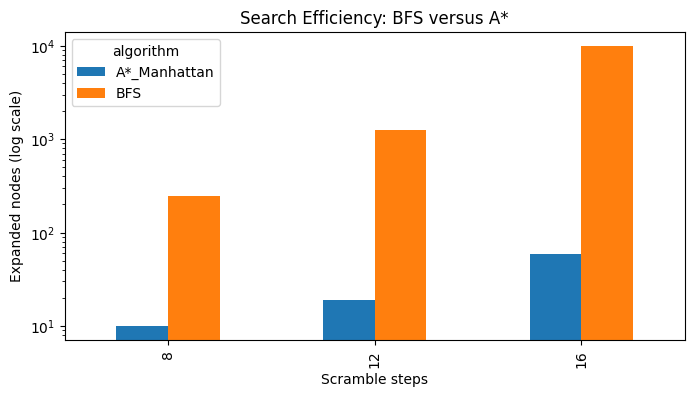

In [4]:
pivot = search_df.pivot(index="scramble_steps", columns="algorithm", values="expanded_nodes")
pivot.plot(kind="bar", figsize=(8, 4))
plt.yscale("log"); plt.xlabel("Scramble steps"); plt.ylabel("Expanded nodes (log scale)")
plt.title("Search Efficiency: BFS versus A*")
plt.show()


## Required Extension

เขียนฟังก์ชัน `misplaced_tiles(state)` แล้วทดลอง A* ด้วย Heuristic ใหม่นี้ เปรียบเทียบ Solution Length, Expanded Nodes และ Runtime กับ Manhattan Distance


,scramble_steps,algorithm,solution_length,expanded_nodes,milliseconds
0,8,BFS,8,246,0.629
1,8,A*_Manhattan,8,10,0.067
2,8,A*_Misplaced,8,22,0.100
3,12,BFS,12,1258,2.073
4,12,A*_Manhattan,12,19,0.098
5,12,A*_Misplaced,12,80,0.312
6,16,BFS,16,9944,18.287
7,16,A*_Manhattan,16,59,0.281
8,16,A*_Misplaced,16,477,2.031


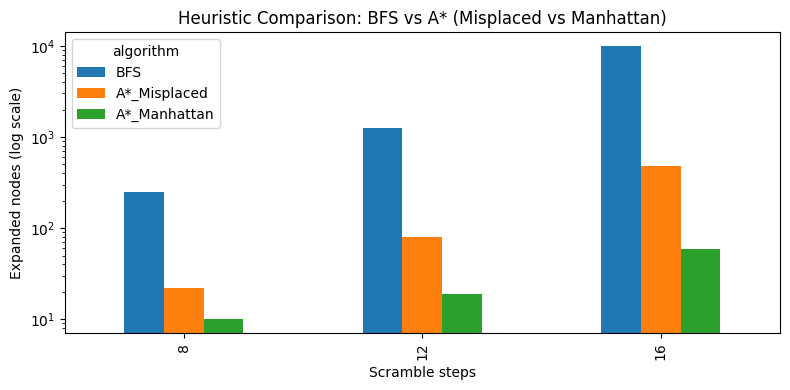

In [5]:
def misplaced_tiles(state):
    # นับจำนวน tile ที่อยู่ผิดตำแหน่ง โดยไม่นับช่องว่าง 0
    return sum(1 for i, tile in enumerate(state) if tile != 0 and tile != GOAL[i])

# รัน A* ด้วย misplaced_tiles บนสถานะเริ่มต้นชุดเดียวกับตารางแรก แล้วเทียบ 3 แบบ
ext_rows = []
for scramble_steps in [8, 12, 16]:
    start = search_df.loc[search_df.scramble_steps == scramble_steps, "start"].iloc[0]
    for algorithm, solver in [
        ("BFS", bfs),
        ("A*_Manhattan", lambda s: astar(s, manhattan)),
        ("A*_Misplaced", lambda s: astar(s, misplaced_tiles)),
    ]:
        begin = time.perf_counter()
        length, expanded = solver(start)
        elapsed = time.perf_counter() - begin
        ext_rows.append([scramble_steps, algorithm, length, expanded, round(elapsed * 1000, 3)])

ext_df = pd.DataFrame(ext_rows, columns=["scramble_steps", "algorithm", "solution_length", "expanded_nodes", "milliseconds"])
display(ext_df)

# กราฟเทียบจำนวน node ที่ขยายของ 3 อัลกอริทึม
ext_pivot = ext_df.pivot(index="scramble_steps", columns="algorithm", values="expanded_nodes")
ext_pivot = ext_pivot[["BFS", "A*_Misplaced", "A*_Manhattan"]]
ext_pivot.plot(kind="bar", figsize=(8, 4))
plt.yscale("log")
plt.xlabel("Scramble steps")
plt.ylabel("Expanded nodes (log scale)")
plt.title("Heuristic Comparison: BFS vs A* (Misplaced vs Manhattan)")
plt.tight_layout()
plt.show()


## คำถามวิเคราะห์ Lab 04

**1. BFS และ A* ให้ Solution Length เท่ากันทุกกรณีหรือไม่ เพราะเหตุใด**

เท่ากันทุกกรณีครับ (8, 12, 16 ตรงกันหมด) เพราะทั้ง BFS และ A* ที่ใช้ heuristic แบบ admissible (ไม่ประเมินเกินจริง) การันตีว่าได้คำตอบสั้นที่สุด (optimal) เหมือนกัน ต่างกันแค่ "วิธีเดินไปหา" ไม่ใช่ "ความยาวคำตอบ"

**2. Manhattan Distance ลด Expanded Nodes ได้มากเพียงใด**

ลดได้เยอะมากครับ ที่ scramble 16 ก้าว BFS ขยายไปเกือบ 10,000 node แต่ A* Manhattan ขยายแค่ ~59 node (ลดกว่า 99%) ยิ่งปัญหายากยิ่งเห็นช่องว่างชัด เพราะ heuristic ช่วยชี้ทางให้ไม่ต้องไล่ทุกทิศ

**3. Heuristic ที่ดีควรมีคุณสมบัติอะไร**

ควร admissible (ไม่ประเมินเกินระยะจริง) เพื่อให้ยังได้คำตอบ optimal, ควร consistent, และควร "ให้ข้อมูลเยอะ" (informed) คือค่ายิ่งใกล้ระยะจริงยิ่งดี จะได้ตัดทางที่ไม่จำเป็นออกได้มาก แต่ก็ต้องคำนวณเร็วด้วย ไม่งั้นประหยัด node แต่ไปเสียเวลาคำนวณแทน

**4. ผลของ Misplaced Tiles ต่างจาก Manhattan อย่างไร**

Misplaced ก็ได้คำตอบสั้นเท่ากัน (optimal เหมือนกัน) แต่ขยาย node มากกว่า Manhattan ชัดเจน (เช่นที่ 16 ก้าว: Misplaced ~477 vs Manhattan ~59) เพราะ Misplaced แค่นับว่ากี่ตัวผิดที่ ให้ข้อมูลน้อยกว่า ส่วน Manhattan บอกด้วยว่าแต่ละตัวต้องขยับไกลแค่ไหน เลย informed กว่าและตัดทางได้ดีกว่า

**5. Human Heuristic กับ AI Heuristic เหมือนหรือต่างกันอย่างไร**

เหมือนตรงที่คนเราก็ใช้ "ลางสังหรณ์/ประสบการณ์" ตัดตัวเลือกให้แคบลงเหมือน heuristic ช่วยตัด node แต่ต่างตรงที่ของคนมักคลุมเครือ ไม่การันตี optimal และจำกัดด้วย working memory เลยมองไปข้างหน้าได้ไม่กี่ก้าว ส่วน AI คำนวณ heuristic ชัดเจนเป็นตัวเลขและไล่ได้เป็นพันสถานะโดยไม่ลืม


## Reflection และ Checklist ก่อนส่ง

เขียน Reflection 150–250 คำ โดยอธิบายส่วนที่ยากที่สุด สิ่งที่ค้นพบเกี่ยวกับกระบวนการรู้คิด และสิ่งที่จะปรับปรุงหากทำการทดลองซ้ำ

**Reflection:**

ส่วนที่ยากสุดสำหรับผมคือทำความเข้าใจ A* ตอนแรกงงว่าทำไมมันขยาย node น้อยกว่า BFS เยอะขนาดนั้นทั้งที่ได้คำตอบยาวเท่ากัน พอไล่โค้ดกับดูค่า heuristic ถึงเข้าใจว่ามันเอา g (ระยะที่เดินมาแล้ว) บวกกับ h (ระยะที่คาดว่าเหลือ) มาจัดคิว เลยเลือกเดินทางที่น่าจะใกล้เป้าก่อน ไม่เสียเวลาไล่มั่วแบบ BFS

สิ่งที่เชื่อมกับ cognitive science คือมันเหมือนการแก้ปัญหาของคน เราไม่ได้ลองทุกความเป็นไปได้ แต่ใช้ heuristic หรือลางสังหรณ์ตัดตัวเลือกให้แคบลง เห็นชัดว่า heuristic ที่ดี (Manhattan) ช่วยประหยัดแรงคิดได้มากกว่าอันที่หยาบกว่า (Misplaced) ซึ่งก็ตรงกับที่คนเก่งๆ มักมี "ลาง" ที่แม่นกว่าคนอื่น

ถ้าทำซ้ำ ผมอยากลอง heuristic อื่นเพิ่ม เช่น linear conflict ที่ informed กว่า Manhattan และอยากลองปัญหาที่ยากขึ้น (scramble เยอะๆ) เพื่อดูว่า BFS จะระเบิดเร็วแค่ไหน รวมถึงอยากวัด runtime หลายรอบเฉลี่ยกันด้วย เพราะรอบเดียวมี noise จากเครื่อง

### เกณฑ์ประเมิน

| ด้าน | คะแนน |
|---|---:|
| ความถูกต้องของโปรแกรมและผลลัพธ์ | 35 |
| กระบวนการวิเคราะห์และความสมเหตุสมผล | 20 |
| กราฟ ตาราง และการสื่อสารผล | 15 |
| การตีความตามหลัก Cognitive Science | 20 |
| คุณภาพโค้ดและ Reflection | 10 |
| **รวม** | **100** |

- [x] เปลี่ยน `STUDENT_ID` แล้ว
- [x] รันทุกเซลล์โดยไม่มี Error
- [x] ทำ Required Extension สำเร็จ
- [x] ตอบคำถามทุกข้อด้วยถ้อยคำของตนเอง
- [x] ตรวจไฟล์ `.ipynb` และ `.pdf` ก่อนส่ง
